# Post 03 — Is the expensive refiner worth it?

**Question:** does predicting the cheap, global shape first — then spending an expensive
model's effort only on what's left over — actually beat running the expensive model on
its own?

This is the premise behind SCALER (Le et al., 2026, KDD — [arXiv:2608.08675](https://arxiv.org/abs/2608.08675),
`literature/scaler-2026.pdf`): a lightweight forecaster predicts a coarse future shape,
then a pretrained LLM spends its (expensive) effort only on refining that shape, scale by
scale. Their version is a fully trained architecture — a custom coarse-shape Transformer
feeding a frozen-but-adapted LLM through a multi-stage token-refinement loop, trained on
standard long-horizon benchmarks. Not something to reproduce here.

What *is* worth testing at small scale: the underlying idea, using nothing but building
blocks this repo already has and has already validated —

- **Coarse shape:** `seasonal_naive_forecast` (Post 01) — free.
- **Cheap refiner:** the nearest-neighbor residual-memory retrieval from Post 01 Demo 2,
  pointed at the coarse model's residual instead of ARIMA's.
- **Expensive refiner:** Chronos-2 zero-shot (Posts 01-02), pointed at that same residual
  series instead of the raw target.
- **Reference point:** Chronos-2 zero-shot on the raw series directly — no coarse anchor
  at all. This is just Post 01 Demo 1's model.

If the premise holds, a cheap shape plus a refiner — especially the *cheap* refiner —
should get close to Chronos-on-raw's accuracy for a fraction of the cost. That's a real
claim with a real chance of being wrong, and worth saying upfront: a quick look at a
handful of individual forecast origins before building this notebook properly showed no
consistent winner at all — which is exactly why this needs the full rolling-origin
harness rather than a few examples eyeballed by hand.

In [1]:
import sys
import warnings

sys.path.insert(0, "../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.coarse_to_fine import coarse_plus_chronos_refiner_forecast, coarse_plus_residual_memory_forecast
from src.data import load_electricity
from src.evaluation import combine_results, mae, rolling_origin_evaluate, summarize
from src.models import chronos_zero_shot_forecast, seasonal_naive_forecast

warnings.filterwarnings("ignore")
RESULTS_DIR = "../../results/03-coarse-to-fine-hybrids"


## Scale

Same pattern as every notebook in this series: `SMALL_SCALE = True` keeps the number of
forecast origins small so this runs in a few minutes.

In [2]:
SMALL_SCALE = True

if SMALL_SCALE:
    CISO_LOOKBACK, VAL_SIZE, TEST_SIZE, STEP = 8_000, 600, 600, 80
else:
    CISO_LOOKBACK, VAL_SIZE, TEST_SIZE, STEP = None, 2_000, 2_000, 12

HORIZONS = {"short": 6, "medium": 24, "long": 168}
HORIZON_VALUES = sorted(HORIZONS.values())

SEASON_LENGTH = 24          # daily cycle
RESIDUAL_MEMORY_LOOKBACK = 48
RESIDUAL_MEMORY_K = 5
CHRONOS_MAX_CONTEXT = 512

REFINEMENT_WEIGHT_GRID = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]


In [3]:
ciso = load_electricity("CISO")
if CISO_LOOKBACK:
    ciso = ciso.iloc[-CISO_LOOKBACK:]

train_size = len(ciso) - VAL_SIZE - TEST_SIZE
val_phase = ciso.iloc[: train_size + VAL_SIZE]   # train + val
test_phase = ciso                                 # train + val + test

print(f"train={train_size}  val={VAL_SIZE}  test={TEST_SIZE}  total={len(ciso)}")
print(f"train range: {ciso.index[0]} -> {ciso.index[train_size - 1]}")


train=6800  val=600  test=600  total=8000
train range: 2025-09-18 17:00:00+00:00 -> 2026-06-29 00:00:00+00:00


## Run all four models over the same origins

One rolling-origin pass over train+val (to fit refinement weights), one over
train+val+test (scored on test). Both refiners run at full weight (1.0, i.e. the raw,
untuned correction) here — the validation-tuned version comes next, reusing these same
results with no extra model calls.

In [4]:
def run_all_models(series, initial_train_size, step):
    seasonal_naive = rolling_origin_evaluate(
        series, seasonal_naive_forecast, "Seasonal naive", HORIZON_VALUES,
        initial_train_size, step=step, model_kwargs={"season_length": SEASON_LENGTH},
    )
    chronos_raw = rolling_origin_evaluate(
        series, chronos_zero_shot_forecast, "Chronos-2 (raw, no anchor)", HORIZON_VALUES,
        initial_train_size, step=step, model_kwargs={"max_context_length": CHRONOS_MAX_CONTEXT},
    )
    coarse_chronos = rolling_origin_evaluate(
        series, coarse_plus_chronos_refiner_forecast, "Coarse + Chronos refiner", HORIZON_VALUES,
        initial_train_size, step=step,
        model_kwargs={"season_length": SEASON_LENGTH, "max_context_length": CHRONOS_MAX_CONTEXT, "weight": 1.0},
    )
    coarse_resmem = rolling_origin_evaluate(
        series, coarse_plus_residual_memory_forecast, "Coarse + residual-memory refiner", HORIZON_VALUES,
        initial_train_size, step=step,
        model_kwargs={
            "season_length": SEASON_LENGTH, "lookback": RESIDUAL_MEMORY_LOOKBACK,
            "k": RESIDUAL_MEMORY_K, "weight": 1.0,
        },
    )
    return {
        "Seasonal naive": seasonal_naive,
        "Chronos-2 (raw, no anchor)": chronos_raw,
        "Coarse + Chronos refiner": coarse_chronos,
        "Coarse + residual-memory refiner": coarse_resmem,
    }


val_results = run_all_models(val_phase, train_size, STEP)
test_results = run_all_models(test_phase, train_size + VAL_SIZE, STEP)


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

## Validation-tuned refinement weight

`coarse + weight * refinement` is a linear blend of the seasonal-naive forecast and the
full-weight (`weight=1.0`) composite forecast already computed above — so tuning the
weight is just `combine_results` on results we already have, no extra model calls.
Weight is chosen per horizon, on validation rows only, before ever touching test.

In [5]:
def refinement_weight_results(coarse_results, full_results, weight, model_name):
    # coarse + rw*refinement == (1-rw)*coarse + rw*full, and combine_results blends as
    # w*a + (1-w)*b -- so passing weight=(1-rw) with a=coarse, b=full gives exactly that.
    if isinstance(weight, dict):
        combine_weight = {h: 1 - rw for h, rw in weight.items()}
    else:
        combine_weight = 1 - weight
    return combine_results(coarse_results, full_results, weight=combine_weight, model_name=model_name)


def fit_refinement_weight_by_horizon(coarse_results, full_results, val_origins):
    weights = {}
    for horizon in HORIZON_VALUES:
        best_weight, best_mae = None, np.inf
        for rw in REFINEMENT_WEIGHT_GRID:
            blended = refinement_weight_results(coarse_results, full_results, rw, "tmp")
            rows = blended[(blended["horizon"] == horizon) & (blended["origin"].isin(val_origins))]
            candidate_mae = mae(rows["actual"], rows["forecast"])
            if candidate_mae < best_mae:
                best_mae, best_weight = candidate_mae, rw
        weights[horizon] = best_weight
    return weights


val_origins = set(val_results["Seasonal naive"]["origin"])

tuned_weights = {}
tuned_test_results = {}
for refiner_name in ["Coarse + Chronos refiner", "Coarse + residual-memory refiner"]:
    weights = fit_refinement_weight_by_horizon(
        val_results["Seasonal naive"], val_results[refiner_name], val_origins,
    )
    tuned_weights[refiner_name] = weights
    tuned = refinement_weight_results(
        test_results["Seasonal naive"], test_results[refiner_name], weights, f"{refiner_name} (tuned)",
    )
    # combine_results zeroes elapsed_seconds (by design -- in Post 01/02 a reader can look up
    # each base model's own cost separately). Here the untuned refiner run IS the tuned
    # version's true cost too: tuning just reweights an already-computed forecast, no extra
    # per-origin work -- so restore the real number instead of letting it read as free.
    tuned = tuned.merge(
        test_results[refiner_name][["origin", "horizon", "elapsed_seconds"]],
        on=["origin", "horizon"], how="left", suffixes=("", "_true"),
    )
    tuned["elapsed_seconds"] = tuned["elapsed_seconds_true"]
    tuned = tuned.drop(columns=["elapsed_seconds_true"])
    tuned_test_results[f"{refiner_name} (tuned)"] = tuned
    print(f"{refiner_name}: validation-selected refinement weight by horizon = {weights}")


Coarse + Chronos refiner: validation-selected refinement weight by horizon = {6: 0.25, 24: 1.0, 168: 0.0}
Coarse + residual-memory refiner: validation-selected refinement weight by horizon = {6: 0.25, 24: 0.0, 168: 0.0}


## Results

In [6]:
all_test_results = pd.concat(list(test_results.values()) + list(tuned_test_results.values()), ignore_index=True)

summary = summarize(all_test_results)
summary["horizon_label"] = summary["horizon"].map({v: k for k, v in HORIZONS.items()})
summary = summary[["model", "horizon", "horizon_label", "n_forecasts", "mae", "rmse", "mase",
                     "directional_accuracy", "mean_elapsed_seconds"]]
summary.to_csv(f"{RESULTS_DIR}/metrics/coarse_to_fine_summary.csv", index=False)
all_test_results.to_csv(f"{RESULTS_DIR}/metrics/coarse_to_fine_test_forecasts.csv", index=False)
summary


,model,horizon,horizon_label,n_forecasts,mae,rmse,mase,directional_accuracy,mean_elapsed_seconds
0,"Chronos-2 (raw, no anchor)",6,short,6,643.831706,873.378278,0.771218,0.833333,0.104688
1,"Chronos-2 (raw, no anchor)",24,medium,6,935.395508,1132.154873,1.118530,0.833333,0.104688
2,"Chronos-2 (raw, no anchor)",168,long,6,1366.825521,2083.310975,1.620451,0.666667,0.104688
3,Coarse + Chronos refiner,6,short,6,760.077507,946.277305,0.915114,0.833333,0.108013
4,Coarse + Chronos refiner,24,medium,6,1229.907335,1623.636707,1.468791,0.666667,0.108013
5,Coarse + Chronos refiner,168,long,6,1383.841028,1992.669410,1.645734,0.500000,0.108013
6,Coarse + Chronos refiner (tuned),6,short,6,1009.990240,1345.611162,1.216839,0.833333,0.108013
7,Coarse + Chronos refiner (tuned),24,medium,6,1229.907335,1623.636707,1.468791,0.666667,0.108013
8,Coarse + Chronos refiner (tuned),168,long,6,1373.000000,2162.362828,1.629080,0.000000,0.108013
9,Coarse + residual-memory refiner,6,short,6,1478.068481,1638.638604,1.772556,0.833333,0.016790


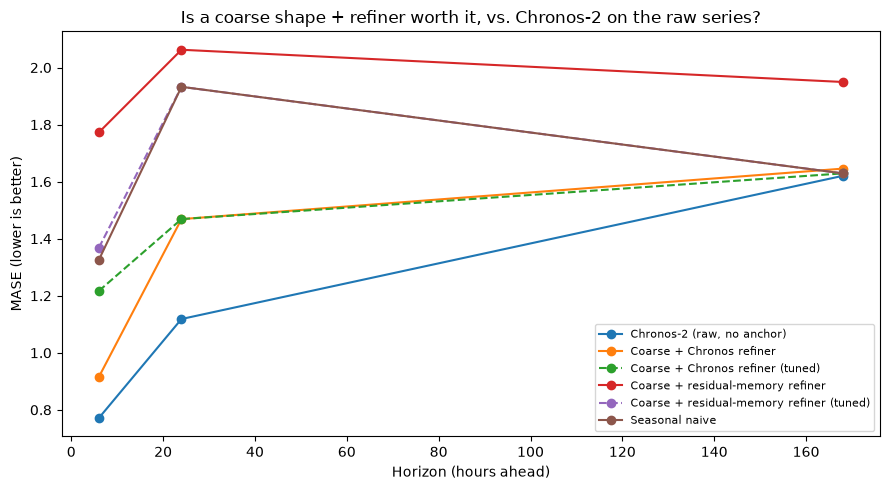

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for model, group in summary.groupby("model"):
    group = group.sort_values("horizon")
    style = "--" if "(tuned)" in model else "-"
    ax.plot(group["horizon"], group["mase"], marker="o", linestyle=style, label=model)
ax.set_xlabel("Horizon (hours ahead)")
ax.set_ylabel("MASE (lower is better)")
ax.set_title("Is a coarse shape + refiner worth it, vs. Chronos-2 on the raw series?")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/mase_by_horizon.png", dpi=150)
plt.show()


## Cost: what did each model actually spend at test time?

`mean_elapsed_seconds` above is per forecast-origin runtime, and the "(tuned)" rows'
numbers have been corrected to match their untuned counterpart -- picking a validation
weight reweights an already-computed forecast, it doesn't add per-origin cost, so letting
`combine_results`' default (which zeroes this column) stand here would make tuning look
free when it isn't.

Don't assume the residual-memory refiner is the cheap option just because it doesn't call
an external model: `retrieve_residual_correction` does a brute-force nearest-neighbor
search over every valid candidate window in the training history, so its cost grows with
how much history there is. At this repo's full CISO history it can end up costing as much
as, or more than, a single Chronos-2 call -- worth checking explicitly rather than
assuming "no pretrained model involved" means "cheap." Seasonal-naive alone is the only
model here that's actually free regardless of scale.

In [8]:
cost_summary = summary[summary["horizon"] == HORIZONS["long"]][["model", "mase", "mean_elapsed_seconds"]].sort_values("mase")
cost_summary


,model,mase,mean_elapsed_seconds
2,"Chronos-2 (raw, no anchor)",1.620451,0.104688
8,Coarse + Chronos refiner (tuned),1.629080,0.108013
17,Seasonal naive,1.629080,0.000068
14,Coarse + residual-memory refiner (tuned),1.629080,0.016790
5,Coarse + Chronos refiner,1.645734,0.108013
11,Coarse + residual-memory refiner,1.949522,0.016790


## One example, made concrete

A single test-period origin at the longest horizon: the coarse shape, both refined
versions, Chronos-on-raw, and what actually happened.

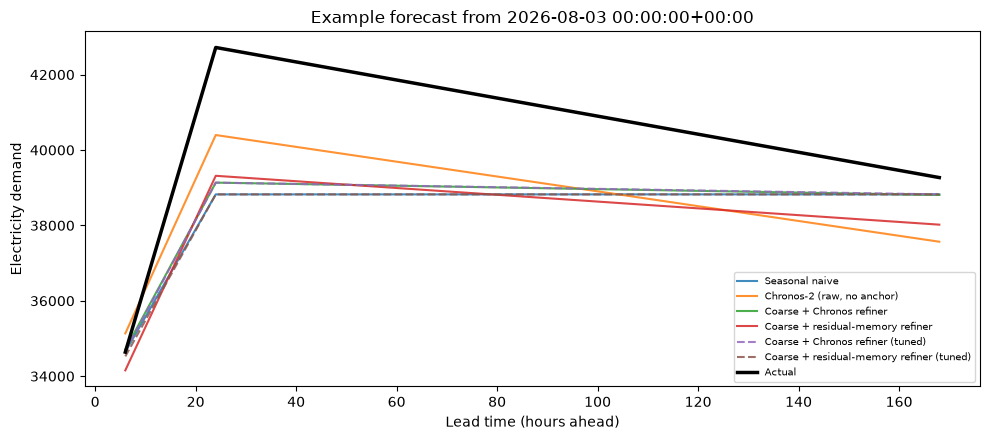

In [9]:
example_origin_date = sorted(test_results["Seasonal naive"]["origin"].unique())[-3]
max_h = HORIZON_VALUES[-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
lead_times = np.arange(1, max_h + 1)

for name, results in {**test_results, **tuned_test_results}.items():
    rows = results[results["origin"] == example_origin_date].sort_values("horizon")
    rows = rows[rows["horizon"] <= max_h]
    if len(rows) == 0:
        continue
    style = "--" if "(tuned)" in name else "-"
    ax.plot(rows["horizon"], rows["forecast"], linestyle=style, label=name, alpha=0.85)

actual_rows = test_results["Seasonal naive"][test_results["Seasonal naive"]["origin"] == example_origin_date].sort_values("horizon")
ax.plot(actual_rows["horizon"], actual_rows["actual"], color="black", linewidth=2.5, label="Actual")

ax.set_xlabel("Lead time (hours ahead)")
ax.set_ylabel("Electricity demand")
ax.set_title(f"Example forecast from {example_origin_date}")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/example_forecast.png", dpi=150)
plt.show()


## Reading the results

- Compare "Coarse + residual-memory refiner (tuned)" and "Coarse + Chronos refiner
  (tuned)" against "Chronos-2 (raw, no anchor)" at each horizon. If neither beats raw
  Chronos, that's the finding, not a failure to report: it would mean Chronos-2 already
  captures CISO's daily/weekly shape well enough on its own that handing it the shape for
  free has nothing left to buy. That's a meaningfully different situation from SCALER's,
  where the refiner is an LLM without native time-series pretraining and visibly benefits
  from an explicit shape anchor — Chronos-2 *is* a time-series specialist already.
- Compare the *untuned* (`weight=1.0`) rows against the validation-tuned rows for each
  refiner. A large gap says the raw correction was mis-scaled (too strong or too weak);
  a small gap says tuning didn't have much to work with either way.
- The validation-selected weights themselves are worth a look (printed above) — a weight
  near 0 at some horizon means validation data found no benefit to that refiner there at
  all, even before touching test.
- `mean_elapsed_seconds` puts a number on the actual selling point of this whole idea:
  if the cheap residual-memory refiner gets anywhere close to Chronos-on-raw's accuracy,
  that is a real, free efficiency win regardless of how the expensive refiner does.
- A handful of hand-picked origins explored before building this notebook showed no
  consistent winner at all between coarse+refiner and Chronos-on-raw — origin-to-origin
  noise alone can flip the ranking. That's exactly why the number to trust is the
  averaged, multi-origin table above, not any single example plot.
- Set `SMALL_SCALE = False` and rerun for the full-scale numbers used in the post.